In [ ]:

# STEP 1: Check GitHub access without downloading the repository

import requests

REPO_API = "https://api.github.com/repos/v7labs/covid-19-xray-dataset"

response = requests.get(REPO_API, timeout=30)
print("GitHub API status:", response.status_code)

response.raise_for_status()
repo_info = response.json()

print("Project:", repo_info["full_name"])
print("Default branch:", repo_info["default_branch"])
print("Repository URL:", repo_info["html_url"])


GitHub API status: 200
Project: v7labs/covid-19-xray-dataset
Default branch: master
Repository URL: https://github.com/v7labs/covid-19-xray-dataset


In [ ]:
import requests

REPO = "v7labs/covid-19-xray-dataset"
API = f"https://api.github.com/repos/{REPO}"

# Get repository information
repo_response = requests.get(API, timeout=30)
repo_response.raise_for_status()
branch = repo_response.json()["default_branch"]

# List repository file paths only (no image downloads)
tree_url = f"{API}/git/trees/{branch}?recursive=1"
tree_response = requests.get(tree_url, timeout=60)
tree_response.raise_for_status()

tree_data = tree_response.json()
files = [
    item["path"]
    for item in tree_data.get("tree", [])
    if item["type"] == "blob"
]

print("Default branch:", branch)
print("Total files listed:", len(files))
print("Tree truncated:", tree_data.get("truncated", False))

# Show likely images and annotation/label files
image_extensions = (".png", ".jpg", ".jpeg", ".webp", ".dcm")
metadata_extensions = (".json", ".csv", ".xml", ".txt", ".yaml", ".yml")

images = [f for f in files if f.lower().endswith(image_extensions)]
metadata = [f for f in files if f.lower().endswith(metadata_extensions)]

print("\n--- IMAGE FILES (first 30) ---")
for f in images[:30]:
    print(f)

print("\n--- ANNOTATION / METADATA FILES (first 50) ---")
for f in metadata[:50]:
    print(f)

print("\n--- README / DOCUMENTATION ---")
for f in files:
    if "readme" in f.lower():
        print(f)

Default branch: master
Total files listed: 6521
Tree truncated: False

--- IMAGE FILES (first 30) ---
annotations/all-images-semantic-masks/1676192.png
annotations/all-images-semantic-masks/1676193.png
annotations/all-images-semantic-masks/1676194.png
annotations/all-images-semantic-masks/1676195.png
annotations/all-images-semantic-masks/1676196.png
annotations/all-images-semantic-masks/1676197.png
annotations/all-images-semantic-masks/1676198.png
annotations/all-images-semantic-masks/1676199.png
annotations/all-images-semantic-masks/1676200.png
annotations/all-images-semantic-masks/1676201.png
annotations/all-images-semantic-masks/1676202.png
annotations/all-images-semantic-masks/1676203.png
annotations/all-images-semantic-masks/1676204.png
annotations/all-images-semantic-masks/1676205.png
annotations/all-images-semantic-masks/1676206.png
annotations/all-images-semantic-masks/1676207.png
annotations/all-images-semantic-masks/1676208.png
annotations/all-images-semantic-masks/1676209.pn

In [ ]:
import requests

REPO = "v7labs/covid-19-xray-dataset"
API = f"https://api.github.com/repos/{REPO}"

# Get README content from GitHub API
response = requests.get(f"{API}/readme", timeout=30)
response.raise_for_status()

readme_info = response.json()
download_url = readme_info["download_url"]

readme_response = requests.get(download_url, timeout=30)
readme_response.raise_for_status()

readme_text = readme_response.text

print("README preview:\n")
print(readme_text[:12000])

README preview:

# COVID-19 xray dataset


![media/covid-chest-xray-cover.jpg](media/covid-chest-xray-cover.jpg)

[BROWSE & DOWNLOAD THE DATASET ON V7 DARWIN HERE](https://darwin.v7labs.com/v7-labs/covid-19-chest-x-ray-dataset)

or run the following command from [Darwin-py](https://v7labs.github.io/darwin-py/) to download the latest version

```bash
pip install darwin-py
darwin dataset pull v7-labs/covid-19-chest-x-ray-dataset:all-images
```

This dataset contains 6500 images of AP/PA chest x-rays with pixel-level polygonal lung segmentations. There are [517 cases](https://github.com/ieee8023/covid-chestxray-dataset) of COVID-19 amongst these.
Use the command below to download only images presenting COVID-19.

```sh
darwin dataset pull v7-labs/covid-19-chest-x-ray-dataset:covid-only
```

**WARNING:** This dataset is not intended for use in clinical diagnostics.

Each image contains:

- Two "Lung" segmentation masks (rendered as polygons, including the posterior region behind the heart)

In [ ]:

import requests

repo_api = "https://api.github.com/repos/v7labs/covid-19-xray-dataset"

response = requests.get(repo_api, timeout=30)
print("GitHub status:", response.status_code)

if response.ok:
    info = response.json()
    print("Repository:", info["full_name"])
    print("Default branch:", info["default_branch"])
else:
    print(response.text[:1000])




GitHub status: 200
Repository: v7labs/covid-19-xray-dataset
Default branch: master


In [ ]:

if response.ok:
    branch = info["default_branch"]
    tree_url = (
        f"https://api.github.com/repos/"
        f"v7labs/covid-19-xray-dataset/git/trees/{branch}?recursive=1"
    )

    tree_response = requests.get(tree_url, timeout=60)
    print("File-list status:", tree_response.status_code)

    if tree_response.ok:
        tree = tree_response.json()
        files = [
            item["path"]
            for item in tree.get("tree", [])
            if item["type"] == "blob"
        ]

        print("Files listed:", len(files))
        print("Listing truncated:", tree.get("truncated", False))

        print("\nPotential image and annotation files:")
        for path in files:
            if path.lower().endswith(
                (".png", ".jpg", ".jpeg", ".webp", ".json", ".csv", ".xml")
            ):
                print(path)
else:
    print("Run Cell 4 successfully first.")


File-list status: 200
Files listed: 6521
Listing truncated: False

Potential image and annotation files:
annotations/all-images-semantic-masks/1676192.png
annotations/all-images-semantic-masks/1676193.png
annotations/all-images-semantic-masks/1676194.png
annotations/all-images-semantic-masks/1676195.png
annotations/all-images-semantic-masks/1676196.png
annotations/all-images-semantic-masks/1676197.png
annotations/all-images-semantic-masks/1676198.png
annotations/all-images-semantic-masks/1676199.png
annotations/all-images-semantic-masks/1676200.png
annotations/all-images-semantic-masks/1676201.png
annotations/all-images-semantic-masks/1676202.png
annotations/all-images-semantic-masks/1676203.png
annotations/all-images-semantic-masks/1676204.png
annotations/all-images-semantic-masks/1676205.png
annotations/all-images-semantic-masks/1676206.png
annotations/all-images-semantic-masks/1676207.png
annotations/all-images-semantic-masks/1676208.png
annotations/all-images-semantic-masks/1676209

In [ ]:

import requests
import pandas as pd
from collections import Counter

BASE = "https://raw.githubusercontent.com/v7labs/covid-19-xray-dataset/master"

# Read segmentation class mapping
mapping_url = (
    f"{BASE}/annotations/all-images-semantic-masks/class_mapping.csv"
)

r = requests.get(mapping_url, timeout=30)
r.raise_for_status()

from io import StringIO
class_mapping = pd.read_csv(StringIO(r.text))

print("=== CLASS MAPPING ===")
print(class_mapping.to_string(index=False))

# Summarize repository paths from Cell 2
print("\n=== TOP-LEVEL DIRECTORIES ===")
top_dirs = Counter(
    path.split("/")[0] for path in files if "/" in path
)
for folder, count in top_dirs.most_common():
    print(f"{folder}: {count} files")

print("\n=== FILE EXTENSIONS ===")
extensions = Counter(
    "." + path.rsplit(".", 1)[-1].lower()
    for path in files if "." in path.split("/")[-1]
)
for ext, count in extensions.most_common(15):
    print(f"{ext}: {count}")


=== CLASS MAPPING ===
 class_idx     class_name
         0 __background__
       127         Ignore
       255           Lung

=== TOP-LEVEL DIRECTORIES ===
annotations: 6512 files
media: 8 files

=== FILE EXTENSIONS ===
.png: 6510
.zip: 6
.md: 1
.swp: 1
.csv: 1
.gif: 1
.jpg: 1


In [ ]:

import requests

API = "https://api.github.com/repos/v7labs/covid-19-xray-dataset/contents"

for folder in ["media", "annotations"]:
    response = requests.get(f"{API}/{folder}", timeout=30)
    response.raise_for_status()
    items = response.json()

    print(f"\n=== {folder.upper()} ===")
    for item in items[:15]:
        print(
            item["name"],
            "| type:", item["type"],
            "| size:", item.get("size", "N/A"),
            "| URL:", item.get("download_url")
        )

print("\n=== README IMAGE REFERENCES ===")
readme_url = (
    "https://raw.githubusercontent.com/"
    "v7labs/covid-19-xray-dataset/master/README.md"
)
response = requests.get(readme_url, timeout=30)
response.raise_for_status()

for line in response.text.splitlines():
    if any(word in line.lower() for word in [
        "image", "download", "source", "dataset", "github.com"
    ]):
        print(line[:300])



=== MEDIA ===
Jun-17-2020_15-21-23.gif | type: file | size: 54499 | URL: https://raw.githubusercontent.com/v7labs/covid-19-xray-dataset/master/media/Jun-17-2020_15-21-23.gif
Screen_Shot_2020-06-17_at_4.21.57_PM.png | type: file | size: 526951 | URL: https://raw.githubusercontent.com/v7labs/covid-19-xray-dataset/master/media/Screen_Shot_2020-06-17_at_4.21.57_PM.png
class_list.png | type: file | size: 74864 | URL: https://raw.githubusercontent.com/v7labs/covid-19-xray-dataset/master/media/class_list.png
covid-chest-xray-cover.jpg | type: file | size: 164223 | URL: https://raw.githubusercontent.com/v7labs/covid-19-xray-dataset/master/media/covid-chest-xray-cover.jpg
example_1.png | type: file | size: 497371 | URL: https://raw.githubusercontent.com/v7labs/covid-19-xray-dataset/master/media/example_1.png
example_2.png | type: file | size: 41149 | URL: https://raw.githubusercontent.com/v7labs/covid-19-xray-dataset/master/media/example_2.png
example_3.png | type: file | size: 104121 | URL: h

In [ ]:

import requests
import zipfile
import io

zip_url = (
    "https://raw.githubusercontent.com/v7labs/"
    "covid-19-xray-dataset/master/annotations/covid-only.zip"
)

response = requests.get(zip_url, timeout=60)
response.raise_for_status()

print("HTTP status:", response.status_code)
print("ZIP size:", round(len(response.content) / (1024 * 1024), 2), "MB")

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    names = z.namelist()

    print("\nTotal files inside ZIP:", len(names))
    print("\nFirst 30 file paths:")
    for name in names[:30]:
        print(name)

    print("\nFile extensions:")
    from collections import Counter
    extensions = Counter(
        "." + name.rsplit(".", 1)[-1].lower()
        for name in names
        if "." in name.split("/")[-1]
    )
    print(extensions)


HTTP status: 200
ZIP size: 3.36 MB

Total files inside ZIP: 517

First 30 file paths:
1676192.json
1676206.json
1676207.json
1676208.json
1676209.json
1676210.json
1676211.json
1676212.json
1676213.json
1676214.json
1676215.json
1676216.json
1676217.json
1676218.json
1676219.json
1676220.json
1676221.json
1676222.json
1676224.json
1676225.json
1676226.json
1676227.json
1676228.json
1676229.json
1676230.json
1676231.json
1676232.json
1676233.json
1676234.json
1676235.json

File extensions:
Counter({'.json': 517})


In [ ]:

import json
import zipfile
import io
import requests

zip_url = (
    "https://raw.githubusercontent.com/v7labs/"
    "covid-19-xray-dataset/master/annotations/covid-only.zip"
)

response = requests.get(zip_url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    json_file = next(
        name for name in z.namelist()
        if name.endswith(".json")
    )

    annotation = json.loads(z.read(json_file).decode("utf-8"))

print("File:", json_file)
print("\nTop-level keys:")
print(list(annotation.keys()))

print("\nFull JSON preview:")
print(json.dumps(annotation, indent=2)[:7000])


File: 1676192.json

Top-level keys:
['image', 'dataset', 'annotated', 'annotations']

Full JSON preview:
{
  "image": {
    "seq": 6434,
    "width": 2000,
    "height": 2000,
    "filename": "00006434.jpg",
    "original_filename": "0a7faa2a.jpg",
    "url": "https://darwin.v7labs.com/api/images/1676192/original?token=952dd84f-7ac8-4251-873f-3b13e304a066",
    "thumbnail_url": "https://darwin.v7labs.com/api/images/1676192/thumbnail?token=952dd84f-7ac8-4251-873f-3b13e304a066",
    "workview_url": "https://darwin.v7labs.com/workview?dataset=901&image=6434"
  },
  "dataset": "COVID-19 Chest X-Ray Dataset",
  "annotated": true,
  "annotations": [
    {
      "name": "Lung",
      "polygon": {
        "path": [
          {
            "x": 1123.0,
            "y": 294
          },
          {
            "x": 1123.0,
            "y": 296
          },
          {
            "x": 1122,
            "y": 297
          },
          {
            "x": 1121,
            "y": 297
          },
   

In [ ]:

import json
import zipfile
import io
import requests
from collections import Counter

zip_url = (
    "https://raw.githubusercontent.com/v7labs/"
    "covid-19-xray-dataset/master/annotations/covid-only.zip"
)

response = requests.get(zip_url, timeout=60)
response.raise_for_status()

annotation_names = Counter()
image_records = []

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    json_files = [
        name for name in z.namelist()
        if name.endswith(".json")
    ]

    for filename in json_files[:10]:
        data = json.loads(z.read(filename).decode("utf-8"))
        image = data.get("image", {})

        record = {
            "json_file": filename,
            "image_filename": image.get("filename"),
            "width": image.get("width"),
            "height": image.get("height"),
            "url": image.get("url"),
            "annotation_count": len(data.get("annotations", []))
        }
        image_records.append(record)

        for item in data.get("annotations", []):
            annotation_names[item.get("name", "UNKNOWN")] += 1

print("Annotation names and counts (first 10 JSON files):")
print(annotation_names)

print("\nImage metadata:")
for record in image_records[:5]:
    print(json.dumps(record, indent=2))

print("\nFirst JSON's non-polygon annotation fields:")
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    sample = json.loads(z.read(json_files[0]).decode("utf-8"))

    for item in sample.get("annotations", []):
        print({
            key: value for key, value in item.items()
            if key != "polygon"
        })
        if item.get("name") != "Lung":
            continue


Annotation names and counts (first 10 JSON files):
Counter({'Lung': 20, 'X-ray': 10, 'Viral Pneumonia': 10, 'COVID-19': 10, 'ICU_admission/Y': 7, 'Sex/M': 6, 'View/AP_Supine': 6, 'Intubation/Y': 6, 'Intubation_present/N': 4, 'Sex/F': 4, 'In_ICU_scan/N': 3, 'Survival/Y': 3, 'Extubated/Y': 3, 'Needed_supplemental_O2/Y': 3, 'Age:45': 3, 'PatientID:318': 3, 'location:Tokyo, Japan': 3, 'Survival/N': 3, 'View/PA': 2, 'In_ICU_scan/Y': 2, 'Intubation_present/Y': 2, 'View/AP': 2, 'Age:67': 2, 'PatientID:320': 2, 'location:London, United Kingdom': 2, 'pO2_saturation:97': 2, 'pO2_saturation:25': 1, 'PatientID:263': 1, 'location:Hannover Medical School, Hannover, Germany': 1, 'Leukocyte_count:7.4': 1, 'Temperature:38.6': 1, 'Age:56': 1, 'PatientID:11': 1, 'location:Sunnybrook Health Sciences Centre, Toronto, Ontario, Canada': 1, 'PatientID:302': 1, 'Age:35': 1, 'location:Eskisehir, Turkey': 1, 'Temperature:37.3': 1, 'ICU_admission/N': 1, 'Age:62': 1, 'PatientID:301': 1, 'Intubation/N': 1, 'locatio

In [ ]:

import json
import zipfile
import io
import requests
from collections import Counter

zip_url = (
    "https://raw.githubusercontent.com/v7labs/"
    "covid-19-xray-dataset/master/annotations/covid-only.zip"
)

response = requests.get(zip_url, timeout=60)
response.raise_for_status()

label_counts = Counter()
patient_ids = set()
image_count = 0
missing_url = 0
missing_patient_id = 0
samples = []

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    json_files = [
        name for name in z.namelist()
        if name.endswith(".json")
    ]

    for filename in json_files:
        data = json.loads(z.read(filename).decode("utf-8"))
        image = data.get("image", {})
        image_count += 1

        if not image.get("url"):
            missing_url += 1

        names = [
            a.get("name", "")
            for a in data.get("annotations", [])
        ]

        label_counts.update(names)

        ids = [n for n in names if n.startswith("PatientID:")]
        if ids:
            patient_ids.update(ids)
        else:
            missing_patient_id += 1

        if len(samples) < 5:
            samples.append({
                "file": filename,
                "patient_ids": ids,
                "has_covid": "COVID-19" in names,
                "has_viral_pneumonia": "Viral Pneumonia" in names,
                "has_xray_tag": "X-ray" in names,
                "url_present": bool(image.get("url"))
            })

print("JSON annotation files:", image_count)
print("Unique patient IDs found:", len(patient_ids))
print("Files missing image URL:", missing_url)
print("Files missing PatientID tag:", missing_patient_id)

print("\nDisease / modality tag counts:")
for label in ["COVID-19", "Viral Pneumonia", "Bacterial Pneumonia",
              "Fungal Pneumonia", "Healthy", "X-ray"]:
    print(f"{label}: {label_counts[label]}")

print("\nSample records:")
for sample in samples:
    print(sample)


JSON annotation files: 517
Unique patient IDs found: 271
Files missing image URL: 0
Files missing PatientID tag: 0

Disease / modality tag counts:
COVID-19: 517
Viral Pneumonia: 517
Bacterial Pneumonia: 0
Fungal Pneumonia: 0
Healthy: 0
X-ray: 457

Sample records:
{'file': '1676192.json', 'patient_ids': ['PatientID:263'], 'has_covid': True, 'has_viral_pneumonia': True, 'has_xray_tag': True, 'url_present': True}
{'file': '1676206.json', 'patient_ids': ['PatientID:318'], 'has_covid': True, 'has_viral_pneumonia': True, 'has_xray_tag': True, 'url_present': True}
{'file': '1676207.json', 'patient_ids': ['PatientID:318'], 'has_covid': True, 'has_viral_pneumonia': True, 'has_xray_tag': True, 'url_present': True}
{'file': '1676208.json', 'patient_ids': ['PatientID:318'], 'has_covid': True, 'has_viral_pneumonia': True, 'has_xray_tag': True, 'url_present': True}
{'file': '1676209.json', 'patient_ids': ['PatientID:320'], 'has_covid': True, 'has_viral_pneumonia': True, 'has_xray_tag': True, 'url_pr

In [ ]:

import json
import zipfile
import io
import requests

zip_url = (
    "https://raw.githubusercontent.com/v7labs/"
    "covid-19-xray-dataset/master/annotations/covid-only.zip"
)

response = requests.get(zip_url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    json_files = sorted(
        name for name in z.namelist()
        if name.endswith(".json")
    )

    checked = 0

    for filename in json_files:
        data = json.loads(z.read(filename).decode("utf-8"))
        image = data.get("image", {})
        url = image.get("url")

        if not url:
            continue

        print("Annotation:", filename)
        print("Image filename:", image.get("filename"))
        print("Dimensions:", image.get("width"), "x", image.get("height"))

        try:
            r = requests.get(
                url,
                headers={"Range": "bytes=0-1023"},
                timeout=20,
                stream=True
            )
            print("HTTP status:", r.status_code)
            print("Content-Type:", r.headers.get("Content-Type"))
            print("Content-Length:", r.headers.get("Content-Length"))
            r.close()
        except requests.RequestException as e:
            print("Request error:", str(e))

        print("-" * 45)
        checked += 1

        if checked == 3:
            break


Annotation: 1676192.json
Image filename: 00006434.jpg
Dimensions: 2000 x 2000
HTTP status: 401
Content-Type: application/json; charset=utf-8
Content-Length: 165
---------------------------------------------
Annotation: 1676206.json
Image filename: 00006448.png
Dimensions: 907 x 689
HTTP status: 401
Content-Type: application/json; charset=utf-8
Content-Length: 165
---------------------------------------------
Annotation: 1676207.json
Image filename: 00006449.png
Dimensions: 913 x 651
HTTP status: 401
Content-Type: application/json; charset=utf-8
Content-Length: 165
---------------------------------------------


In [ ]:

!darwin dataset pull --help


usage: darwin dataset pull [-h] [-t TEAM] [--only-annotations] [--folders]
                           [--no-folders] [--video-frames] [--retry]
                           [--no-multi-processed]
                           [--retry-timeout RETRY_TIMEOUT]
                           [--retry-interval RETRY_INTERVAL] [--force-slots |
                           --ignore-slots]
                           dataset

positional arguments:
  dataset               Remote dataset name to download.

options:
  -h, --help            show this help message and exit
  -t, --team TEAM       Overrides the team to use for the operation. If not
                        provided, the team will be inferred from the dataset
                        slug.
  --only-annotations    Download only annotations and no corresponding images.
  --folders             Recreates image folders.
  --no-folders          Does not recreate image folders.
  --video-frames        Pulls video frame images instead of video files.
  --

In [ ]:

!darwin --help


usage: darwin [-h]
              {help,authenticate,compression,team,convert,validate,dataset,report,version,extract} ...

Command line tool to create/upload/download datasets on darwin.

positional arguments:
  {help,authenticate,compression,team,convert,validate,dataset,report,version,extract}
    help                Show this help message and exit.
    authenticate        Authenticate the user.
    compression         Set compression level.
    team                List or pick teams.
    convert             Converts darwin json to other annotation formats.
    validate            Validate annotation files against Darwin schema
    dataset             Dataset related functions.
    report              Report related functions.
    version             Check current version of the repository.
    extract             Extract and process media files

options:
  -h, --help            show this help message and exit


In [ ]:

!darwin authenticate --help


usage: darwin authenticate [-h] [--api_key API_KEY]
                           [--default_team DEFAULT_TEAM]
                           [--datasets_dir DATASETS_DIR]

options:
  -h, --help            show this help message and exit
  --api_key API_KEY     API key to use.
  --default_team DEFAULT_TEAM
                        Default team to use.
  --datasets_dir DATASETS_DIR
                        Folder to store datasets.


In [ ]:

from getpass import getpass
import subprocess

api_key = getpass("Enter your Darwin API key: ")

result = subprocess.run(
    ["darwin", "authenticate", "--api_key", api_key],
    capture_output=True,
    text=True
)

api_key = None

print("Return code:", result.returncode)
print(result.stdout)

if result.returncode != 0:
    print("Error output:", result.stderr)


KeyboardInterrupt: Interrupted by user

In [ ]:

import requests

url = "https://raw.githubusercontent.com/ieee8023/covid-chestxray-dataset/master/metadata.csv"

response = requests.get(url, timeout=30)

print("HTTP status:", response.status_code)

if response.ok:
    print(response.text[:1000])
else:
    print("Could not retrieve metadata:", response.text[:300])


HTTP status: 200
patientid,offset,sex,age,finding,RT_PCR_positive,survival,intubated,intubation_present,went_icu,in_icu,needed_supplemental_O2,extubated,temperature,pO2_saturation,leukocyte_count,neutrophil_count,lymphocyte_count,view,modality,date,location,folder,filename,doi,url,license,clinical_notes,other_notes,
2,0,M,65,Pneumonia/Viral/COVID-19,Y,Y,N,N,N,N,Y,,,,,,,PA,X-ray,"January 22, 2020","Cho Ray Hospital, Ho Chi Minh City, Vietnam",images,auntminnie-a-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg,10.1056/nejmc2001272,https://www.nejm.org/doi/full/10.1056/NEJMc2001272,,"On January 22, 2020, a 65-year-old man with a history of hypertension, type 2 diabetes, coronary heart disease for which a stent had been implanted, and lung cancer was admitted to the emergency department of Cho Ray Hospital, the referral hospital in Ho Chi Minh City, for low-grade fever and fatigue. He had become ill with fever on January 17, a total of 4 days after he and his wife had flown to Ha

In [ ]:

import pandas as pd
from io import BytesIO
import requests

metadata_url = (
    "https://raw.githubusercontent.com/ieee8023/"
    "covid-chestxray-dataset/master/metadata.csv"
)

response = requests.get(metadata_url, timeout=30)
response.raise_for_status()

df = pd.read_csv(BytesIO(response.content))

print("Total metadata records:", len(df))
print("\nModality counts:")
print(df["modality"].value_counts(dropna=False).head(10))

print("\nFinding counts (top 15):")
print(df["finding"].value_counts(dropna=False).head(15))

print("\nCOVID-19 finding records:")
covid = df[
    df["finding"].astype(str).str.contains(
        "COVID-19", case=False, na=False
    )
]
print(len(covid))

print("\nCOVID-19 records by view:")
print(covid["view"].value_counts(dropna=False))

print("\nSample COVID-19 records:")
print(
    covid[["patientid", "finding", "view", "modality", "filename"]]
    .head(10)
    .to_string(index=False)
)


Total metadata records: 950

Modality counts:
modality
X-ray    866
CT        84
Name: count, dtype: int64

Finding counts (top 15):
finding
Pneumonia/Viral/COVID-19             584
todo                                  83
Pneumonia                             81
Pneumonia/Fungal/Pneumocystis         30
Pneumonia/Bacterial/Streptococcus     22
No Finding                            22
Tuberculosis                          18
Pneumonia/Viral/SARS                  16
Pneumonia/Lipoid                      13
Pneumonia/Bacterial/Mycoplasma        11
Pneumonia/Viral/MERS-CoV              10
Pneumonia/Bacterial/Klebsiella        10
Pneumonia/Bacterial/Legionella        10
Pneumonia/Bacterial/Nocardia           8
Pneumonia/Viral/Varicella              6
Name: count, dtype: int64

COVID-19 finding records:
584

COVID-19 records by view:
view
PA           196
AP           146
AP Supine    136
Axial         64
L             26
Coronal       16
Name: count, dtype: int64

Sample COVID-19 records:
p

In [ ]:

# Filter COVID-19 chest X-rays; do not download yet.
covid_xray = df[
    df["finding"].astype(str).str.contains(
        "COVID-19", case=False, na=False
    )
    & df["modality"].astype(str).str.strip().str.lower().eq("x-ray")
].copy()

# Keep frontal views for the initial experiment.
frontal_views = ["PA", "AP", "AP Supine"]

covid_frontal = covid_xray[
    covid_xray["view"].astype(str).str.strip().isin(frontal_views)
].copy()

print("COVID-19 records, all modalities:", len(covid))
print("COVID-19 X-ray records:", len(covid_xray))
print("COVID-19 frontal X-ray records:", len(covid_frontal))

print("\nFrontal view counts:")
print(covid_frontal["view"].value_counts(dropna=False))

print("\nUnique patients in frontal records:",
      covid_frontal["patientid"].nunique())

print("Missing patient IDs:",
      covid_frontal["patientid"].isna().sum())

print("Missing filenames:",
      covid_frontal["filename"].isna().sum())

print("Duplicate filenames:",
      covid_frontal["filename"].duplicated().sum())

print("Patients with multiple frontal images:",
      (covid_frontal.groupby("patientid").size() > 1).sum())

print("\nSample filenames:")
print(
    covid_frontal[
        ["patientid", "view", "filename", "license"]
    ].head(10).to_string(index=False)
)


COVID-19 records, all modalities: 584
COVID-19 X-ray records: 504
COVID-19 frontal X-ray records: 478

Frontal view counts:
view
PA           196
AP           146
AP Supine    136
Name: count, dtype: int64

Unique patients in frontal records: 295
Missing patient IDs: 0
Missing filenames: 0
Duplicate filenames: 0
Patients with multiple frontal images: 110

Sample filenames:
patientid view                                                               filename license
        2   PA auntminnie-a-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg     NaN
        2   PA auntminnie-b-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg     NaN
        2   PA auntminnie-c-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg     NaN
        2   PA auntminnie-d-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg     NaN
        4   PA                                                  nejmc2001573_f1a.jpeg     NaN
        4   PA                                              

In [ ]:

from urllib.parse import urlparse
import requests

print("Metadata URL fields available:")
print([c for c in df.columns if "url" in c.lower()])

print("\nSample COVID image source URLs:")
print(
    covid_frontal[
        ["patientid", "filename", "url"]
    ].head(5).to_string(index=False)
)

print("\nChecking first 3 image URLs...")

for _, row in covid_frontal.head(3).iterrows():
    url = str(row["url"]).strip()

    # Metadata URLs can contain Markdown link formatting.
    if url.startswith("[") and "](" in url:
        url = url.split("](", 1)[1].rstrip(")")

    try:
        r = requests.get(
            url,
            headers={"Range": "bytes=0-1023"},
            timeout=20,
            stream=True
        )
        print(
            row["filename"],
            "| status:", r.status_code,
            "| type:", r.headers.get("Content-Type")
        )
        r.close()
    except requests.RequestException as e:
        print(row["filename"], "| ERROR:", str(e))


Metadata URL fields available:
['url']

Sample COVID image source URLs:
patientid                                                               filename                                                url
        2 auntminnie-a-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg https://www.nejm.org/doi/full/10.1056/NEJMc2001272
        2 auntminnie-b-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg https://www.nejm.org/doi/full/10.1056/NEJMc2001272
        2 auntminnie-c-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg https://www.nejm.org/doi/full/10.1056/NEJMc2001272
        2 auntminnie-d-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg https://www.nejm.org/doi/full/10.1056/NEJMc2001272
        4                                                  nejmc2001573_f1a.jpeg https://www.nejm.org/doi/full/10.1056/NEJMc2001573

Checking first 3 image URLs...
auntminnie-a-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg | status: 403 | type: text/html; 

In [ ]:

from urllib.parse import quote
import requests

base_url = (
    "https://raw.githubusercontent.com/ieee8023/"
    "covid-chestxray-dataset/master/images/"
)

for filename in covid_frontal["filename"].head(5):
    image_url = base_url + quote(str(filename), safe="")

    try:
        r = requests.get(
            image_url,
            stream=True,
            timeout=20
        )

        print(
            filename,
            "| HTTP:", r.status_code,
            "| Content-Type:", r.headers.get("Content-Type")
        )

        r.close()

    except requests.RequestException as e:
        print(filename, "| ERROR:", str(e))


auntminnie-a-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg | HTTP: 200 | Content-Type: image/jpeg
auntminnie-b-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg | HTTP: 200 | Content-Type: image/jpeg
auntminnie-c-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg | HTTP: 200 | Content-Type: image/jpeg
auntminnie-d-2020_01_28_23_51_6665_2020_01_28_Vietnam_coronavirus.jpeg | HTTP: 200 | Content-Type: image/jpeg
nejmc2001573_f1a.jpeg | HTTP: 200 | Content-Type: image/jpeg


In [ ]:

import os
import time
import requests
import pandas as pd
from urllib.parse import quote
from PIL import Image, UnidentifiedImageError
from io import BytesIO

BASE_URL = (
    "https://raw.githubusercontent.com/ieee8023/"
    "covid-chestxray-dataset/master/images/"
)
OUTPUT_DIR = "/content/covid_xray_data/COVID"
os.makedirs(OUTPUT_DIR, exist_ok=True)

session = requests.Session()
manifest = []

# One entry per metadata record; filenames are preserved.
for i, row in enumerate(covid_frontal.itertuples(index=False), start=1):
    filename = str(row.filename)
    patient_id = str(row.patientid)
    url = BASE_URL + quote(filename, safe="")
    save_path = os.path.join(OUTPUT_DIR, filename)

    status = "failed"
    detail = ""

    try:
        if os.path.exists(save_path) and os.path.getsize(save_path) > 0:
            with open(save_path, "rb") as f:
                content = f.read()
        else:
            response = session.get(url, timeout=30)
            response.raise_for_status()
            content = response.content

        # Verify the downloaded bytes decode as an image.
        with Image.open(BytesIO(content)) as img:
            img.verify()

        # Save only after successful verification.
        with open(save_path, "wb") as f:
            f.write(content)

        status = "downloaded"
        detail = f"{len(content)} bytes"

    except (requests.RequestException, UnidentifiedImageError,
            OSError, ValueError) as e:
        detail = str(e)

    manifest.append({
        "patientid": patient_id,
        "filename": filename,
        "view": str(row.view),
        "url": url,
        "local_path": save_path if status == "downloaded" else "",
        "status": status,
        "detail": detail
    })

    if i % 50 == 0:
        print(f"Processed {i}/{len(covid_frontal)}")

    time.sleep(0.03)  # Be considerate to the public repository.

manifest_df = pd.DataFrame(manifest)
manifest_path = "/content/covid_download_manifest.csv"
manifest_df.to_csv(manifest_path, index=False)

print("\nDownload summary:")
print(manifest_df["status"].value_counts(dropna=False))
print("Unique downloaded patients:",
      manifest_df.loc[
          manifest_df.status == "downloaded", "patientid"
      ].nunique())
print("Manifest saved to:", manifest_path)


Processed 50/478
Processed 100/478
Processed 150/478
Processed 200/478
Processed 250/478
Processed 300/478
Processed 350/478
Processed 400/478
Processed 450/478

Download summary:
status
downloaded    478
Name: count, dtype: int64
Unique downloaded patients: 295
Manifest saved to: /content/covid_download_manifest.csv


In [ ]:

import requests
from bs4 import BeautifulSoup

dataset_page = "https://data.mendeley.com/datasets/rscbjbr9sj/2"

try:
    response = requests.get(
        dataset_page,
        timeout=30,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    print("HTTP status:", response.status_code)
    print("Final URL:", response.url)

    if response.ok:
        soup = BeautifulSoup(response.text, "html.parser")
        print("Page title:", soup.title.get_text(strip=True) if soup.title else "Not found")
        print("\nPage preview:")
        print(soup.get_text(" ", strip=True)[:1200])
    else:
        print("Page could not be read directly.")
        print(response.text[:300])

except requests.RequestException as e:
    print("Request error:", e)


HTTP status: 200
Final URL: https://data.mendeley.com/datasets/rscbjbr9sj/2
Page title: Labeled Optical Coherence Tomography (OCT) and Chest X-Ray Images for Classification - Mendeley Data

Page preview:
Labeled Optical Coherence Tomography (OCT) and Chest X-Ray Images for Classification - Mendeley Data Skip to main content FAQ Sign In / Register Sign In / Register FAQ Labeled Optical Coherence Tomography (OCT) and Chest X-Ray Images for Classification Published: 6 January 2018 | Version 2 | DOI: 10.17632/rscbjbr9sj.2 Contributors : Daniel Kermany , Kang Zhang , Michael Goldbaum Description Dataset of validated OCT and Chest X-Ray images  described and analyzed in "Deep learning-based classification and referral of treatable human diseases". The OCT Images are split into a training set and a testing set of independent patients. OCT Images are labeled as (disease)-(randomized patient ID)-(image number by this patient) and split into 4 directories: CNV, DME, DRUSEN, and NORMAL. Download 

In [ ]:

import os
import shutil

PROJECT_DIR = "/content/covid_xray_project"

folders = [
    "data/COVID",
    "data/Normal",
    "data/Pneumonia",
    "manifests",
    "models",
    "results",
    "app"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

total, used, free = shutil.disk_usage("/content")

print("Project directory:", PROJECT_DIR)
print(f"Disk total: {total / (1024**3):.2f} GB")
print(f"Disk used:  {used / (1024**3):.2f} GB")
print(f"Disk free:  {free / (1024**3):.2f} GB")

print("\nWorkspace folders:")
for folder in folders:
    print("✓", folder)


Project directory: /content/covid_xray_project
Disk total: 112.64 GB
Disk used:  42.80 GB
Disk free:  69.82 GB

Workspace folders:
✓ data/COVID
✓ data/Normal
✓ data/Pneumonia
✓ manifests
✓ models
✓ results
✓ app


In [ ]:

import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

page_url = "https://data.mendeley.com/datasets/rscbjbr9sj/2"

response = requests.get(
    page_url,
    timeout=30,
    headers={"User-Agent": "Mozilla/5.0"}
)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

print("Page title:", soup.title.get_text(strip=True) if soup.title else "Unknown")
print("\nLinks that may lead to dataset files:")

seen = set()

for a in soup.find_all("a", href=True):
    href = urljoin(page_url, a["href"])
    text = a.get_text(" ", strip=True)

    if any(term in href.lower() for term in [
        "/files/", "download", "filedownload", "api"
    ]):
        if href not in seen:
            seen.add(href)
            print(f"Text: {text[:100]}")
            print(f"URL:  {href}\n")

print("Candidate links found:", len(seen))


Page title: Labeled Optical Coherence Tomography (OCT) and Chest X-Ray Images for Classification - Mendeley Data

Links that may lead to dataset files:
Text: API Docs
URL:  https://data.mendeley.com/api/docs

Candidate links found: 1


In [ ]:

import requests

API = "https://api.data.mendeley.com"
candidates = [
    ("rscbjbr9sj", 2),
    ("10.17632/rscbjbr9sj.2", None),
]

dataset_info = None

for dataset_id, version in candidates:
    params = {}
    if version is not None:
        params["version"] = version

    url = f"{API}/datasets/{dataset_id}"

    try:
        r = requests.get(url, params=params, timeout=30)
        print("\nTrying:", r.url)
        print("HTTP status:", r.status_code)

        if r.ok:
            data = r.json()
            if isinstance(data, dict):
                dataset_info = data
                print("Top-level keys:", list(data.keys()))

                for key in ["id", "name", "version", "doi", "files"]:
                    if key in data:
                        value = data[key]
                        if key == "files" and isinstance(value, list):
                            print("Number of listed files:", len(value))
                            for f in value[:10]:
                                print({
                                    "filename": f.get("filename"),
                                    "id": f.get("id"),
                                    "size": f.get("size"),
                                    "content_details": f.get("content_details")
                                })
                        else:
                            print(f"{key}:", str(value)[:500])
                break
        else:
            print("Response preview:", r.text[:250])

    except Exception as e:
        print("Request failed:", str(e))

if dataset_info is None:
    print("\nNo dataset metadata retrieved. We'll try the documented files endpoint next.")



Trying: https://api.data.mendeley.com/datasets/rscbjbr9sj?version=2
HTTP status: 401
Response preview: {"message":"Unauthorized (no suitable authorization credentials were provided)"}

Trying: https://api.data.mendeley.com/datasets/10.17632/rscbjbr9sj.2
HTTP status: 404
Response preview: {
  "message":"no Route matched with those values",
  "request_id":"27216d5077af4829cb2e1e7d82bc1962"
}

No dataset metadata retrieved. We'll try the documented files endpoint next.


In [ ]:

import requests
from bs4 import BeautifulSoup

url = "https://data.mendeley.com/datasets/9xkhgts2s6/2"

r = requests.get(
    url,
    timeout=30,
    headers={"User-Agent": "Mozilla/5.0"}
)

print("HTTP status:", r.status_code)

if r.ok:
    soup = BeautifulSoup(r.text, "html.parser")
    print("Title:", soup.title.get_text(strip=True) if soup.title else "Not found")

    text = soup.get_text(" ", strip=True)
    for term in ["Files", "Download All", "Licence", "COVID-19"]:
        pos = text.find(term)
        print(f"\n{term}:")
        print(text[pos:pos+500] if pos >= 0 else "Not found")

    print("\nPossible file links:")
    for a in soup.find_all("a", href=True):
        href = a["href"]
        if any(x in href.lower() for x in ["download", "/files/", ".zip"]):
            print(a.get_text(" ", strip=True), href)
else:
    print(r.text[:300])


HTTP status: 200
Title: Curated Dataset for COVID-19 Posterior-Anterior Chest Radiography Images (X-Rays) - Mendeley Data

Files:
Files Institutions Indian Institute of Science PES University M S Ramaiah Institute of Technology Concordia University Categories Radiology, Diagnosis, Pneumonia, Severe Acute Respiratory Syndrome, Chest Imaging, X-Ray Imaging, X-Ray, Coronavirus, Bacterial Pneumonia, Viral Pneumonia, Radiography of Chest, Chest Radiology, Flu Pandemic, Severe Acute Respiratory Syndrome Coronavirus 2, COVID-19 Related Links Dataset https://figshare.com/articles/COVID-19_Chest_X-Ray_Image_Repository/12580328 is c

Download All:
Download All Files Institutions Indian Institute of Science PES University M S Ramaiah Institute of Technology Concordia University Categories Radiology, Diagnosis, Pneumonia, Severe Acute Respiratory Syndrome, Chest Imaging, X-Ray Imaging, X-Ray, Coronavirus, Bacterial Pneumonia, Viral Pneumonia, Radiography of Chest, Chest Radiology, Flu Pandemic, Se

In [ ]:

import requests

API_URL = "https://api.figshare.com/v2/articles/12580328"

response = requests.get(API_URL, timeout=30)
print("HTTP status:", response.status_code)
response.raise_for_status()

article = response.json()

print("Title:", article.get("title"))
print("DOI:", article.get("doi"))
print("Version:", article.get("version"))
print("\nFiles:")

for file_info in article.get("files", []):
    print({
        "name": file_info.get("name"),
        "size_MB": round(file_info.get("size", 0) / (1024 * 1024), 2),
        "download_url": file_info.get("download_url")
    })


HTTP status: 200
Title: COVID-19 Chest X-Ray Image Repository
DOI: 10.6084/m9.figshare.12580328.v3
Version: 3

Files:
{'name': 'covid_cxnet_dataset.zip', 'size_MB': 189.43, 'download_url': 'https://ndownloader.figshare.com/files/28093332'}


In [ ]:
import os
import requests
import zipfile

ZIP_URL = "https://ndownloader.figshare.com/files/28093332"
ZIP_PATH = "/content/covid_cxnet_dataset.zip"
EXTRACT_DIR = "/content/covid_cxnet_dataset"

os.makedirs(EXTRACT_DIR, exist_ok=True)

if not os.path.exists(ZIP_PATH) or os.path.getsize(ZIP_PATH) < 1000:
    print("Downloading dataset...")

    with requests.get(ZIP_URL, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        downloaded = 0

        with open(ZIP_PATH, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
                    downloaded += len(chunk)

                    if total:
                        print(
                            f"\rDownloaded: {downloaded / 1024**2:.1f} / "
                            f"{total / 1024**2:.1f} MB",
                            end=""
                        )

    print("\nDownload complete!")
else:
    print("ZIP already downloaded:", ZIP_PATH)

print("ZIP size:", round(os.path.getsize(ZIP_PATH) / 1024**2, 2), "MB")

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    print("Checking ZIP integrity...")
    bad_file = z.testzip()

    if bad_file:
        raise RuntimeError(f"Corrupt ZIP member: {bad_file}")

    print("ZIP is valid.")
    print("\nFirst 30 archive entries:")
    for name in z.namelist()[:30]:
        print(name)

    print("\nExtracting dataset...")
    z.extractall(EXTRACT_DIR)

print("\nExtracted to:", EXTRACT_DIR)

Downloaded: 189.4 / 189.4 MB
Download complete!
ZIP size: 189.43 MB
Checking ZIP integrity...
ZIP is valid.

First 30 archive entries:
covid19/
covid19/001.jpeg
covid19/002.jpeg
covid19/003.jpeg
covid19/004.jpeg
covid19/005.jpeg
covid19/006.jpeg
covid19/007.jpg
covid19/008.jpg
covid19/009.jpg
covid19/010.jpeg
covid19/011.jpeg
covid19/012.jpeg
covid19/013.jpeg
covid19/014.jpeg
covid19/015.jpeg
covid19/016.jpeg
covid19/017.jpeg
covid19/018.jpeg
covid19/019.jpeg
covid19/020.jpg
covid19/021.jpg
covid19/022.jpg
covid19/023.jpeg
covid19/024.jpg
covid19/025.jpg
covid19/026.jpg
covid19/027.jpg
covid19/028.jpg
covid19/029.jpg

Extracting dataset...

Extracted to: /content/covid_cxnet_dataset


In [ ]:
import os
from collections import Counter
from PIL import Image

DATASET_DIR = "/content/covid_cxnet_dataset"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_counts = Counter()
image_shapes = Counter()
corrupt_images = []
sample_paths = []

for root, dirs, files in os.walk(DATASET_DIR):
    for filename in files:
        if os.path.splitext(filename)[1].lower() not in image_extensions:
            continue

        path = os.path.join(root, filename)
        relative_path = os.path.relpath(path, DATASET_DIR)
        class_name = relative_path.split(os.sep)[0]
        class_counts[class_name] += 1

        if len(sample_paths) < 10:
            sample_paths.append(path)

        try:
            with Image.open(path) as img:
                img.verify()

            with Image.open(path) as img:
                image_shapes[img.format] += 1

        except Exception as e:
            corrupt_images.append((relative_path, str(e)))

print("DATASET FOLDER:", DATASET_DIR)
print("\nImage counts by top-level folder:")
for name, count in class_counts.items():
    print(f"{name}: {count}")

print("\nTotal images:", sum(class_counts.values()))
print("Image formats:", dict(image_shapes))
print("Corrupt/unreadable images:", len(corrupt_images))

if corrupt_images:
    print("Examples:", corrupt_images[:5])

print("\nSample image paths:")
for path in sample_paths:
    print(path)

DATASET FOLDER: /content/covid_cxnet_dataset

Image counts by top-level folder:
covid19: 863

Total images: 863
Image formats: {'JPEG': 512, 'PNG': 340, 'WEBP': 11}
Corrupt/unreadable images: 0

Sample image paths:
/content/covid_cxnet_dataset/covid19/191.jpeg
/content/covid_cxnet_dataset/covid19/346.jpg
/content/covid_cxnet_dataset/covid19/561.png
/content/covid_cxnet_dataset/covid19/500.jpg
/content/covid_cxnet_dataset/covid19/593.png
/content/covid_cxnet_dataset/covid19/114.jpeg
/content/covid_cxnet_dataset/covid19/546.png
/content/covid_cxnet_dataset/covid19/222.jpeg
/content/covid_cxnet_dataset/covid19/050.jpg
/content/covid_cxnet_dataset/covid19/608.png


In [ ]:
import requests
from bs4 import BeautifulSoup

url = "https://data.mendeley.com/datasets/mxc6vb7svm/1"

response = requests.get(
    url,
    timeout=30,
    headers={"User-Agent": "Mozilla/5.0"}
)

print("HTTP status:", response.status_code)

if response.status_code == 200:
    soup = BeautifulSoup(response.text, "html.parser")

    print("\nPage title:")
    print(soup.title.get_text(strip=True) if soup.title else "Not found")

    page_text = soup.get_text(" ", strip=True)

    for keyword in [
        "COVID", "Pneumonia", "Normal",
        "6939", "Download", "CC BY"
    ]:
        print(f"\n{keyword} mentioned:", keyword.lower() in page_text.lower())

    print("\nPage text preview:")
    print(page_text[:2500])
else:
    print(response.text[:1000])

HTTP status: 200

Page title:
COVID19, Pneumonia and Normal Chest X-ray PA Dataset - Mendeley Data

COVID mentioned: True

Pneumonia mentioned: True

Normal mentioned: True

6939 mentioned: True

Download mentioned: True

CC BY mentioned: True

Page text preview:
COVID19, Pneumonia and Normal Chest X-ray PA Dataset - Mendeley Data Skip to main content FAQ Sign In / Register Sign In / Register FAQ COVID19, Pneumonia and Normal Chest X-ray PA Dataset Published: 22 March 2021 | Version 1 | DOI: 10.17632/mxc6vb7svm.1 Contributors : Amanullah Asraf , Zabirul Islam Description The dataset is organized into 3 folders (covid, pneumonia , normal) which contain chest X-ray posteroanterior (PA) images. X-ray samples of COVID-19 were retrieved from different sources for the unavailability of a large specific dataset. Firstly, a total 1401 samples of COVID-19 were collected using GitHub repository [1] , [2] , the Radiopaedia [3] , Italian Society of Radiology (SIRM) [4] , Figshare data repository w

In [ ]:
import requests
from bs4 import BeautifulSoup

url = "https://data.mendeley.com/datasets/mxc6vb7svm/1"

response = requests.get(
    url,
    timeout=30,
    headers={"User-Agent": "Mozilla/5.0"}
)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

print("Dataset:", soup.title.get_text(strip=True))

print("\nRelevant links found on the page:\n")

for a in soup.find_all("a", href=True):
    text = a.get_text(" ", strip=True)
    href = a["href"]

    if any(word in (text + " " + href).lower()
           for word in ["download", "file", "zip", "dataset"]):
        print("Text:", text[:120])
        print("URL:", href)
        print("-" * 60)

print("\nPage mentions:")
page_text = soup.get_text(" ", strip=True)

for term in ["2313", "augmented", "COVID", "pneumonia", "normal"]:
    print(f"{term}: {term.lower() in page_text.lower()}")

Dataset: COVID19, Pneumonia and Normal Chest X-ray PA Dataset - Mendeley Data

Relevant links found on the page:

Text: Skip to main content
URL: /datasets/mxc6vb7svm/1#main
------------------------------------------------------------
Text: https://figshare.com/articles/dataset/COVID-19_Chest_X-Ray_Image_Repository/12580328/2
URL: https://figshare.com/articles/dataset/COVID-19_Chest_X-Ray_Image_Repository/12580328/2
------------------------------------------------------------
Text: https://data.mendeley.com/datasets/2fxz4px6d8/4
URL: https://data.mendeley.com/datasets/2fxz4px6d8/4
------------------------------------------------------------
Text: File Formats
URL: /file-formats
------------------------------------------------------------

Page mentions:
2313: True
augmented: True
COVID: True
pneumonia: True
normal: True


In [ ]:
import requests
from bs4 import BeautifulSoup

urls = [
    "https://data.mendeley.com/datasets/2fxz4px6d8/4",
    "https://figshare.com/articles/dataset/COVID-19_Chest_X-Ray_Image_Repository/12580328/2"
]

for url in urls:
    print("\n" + "=" * 80)
    print("Checking:", url)

    try:
        r = requests.get(
            url,
            timeout=30,
            headers={"User-Agent": "Mozilla/5.0"}
        )
        print("HTTP status:", r.status_code)
        r.raise_for_status()

        soup = BeautifulSoup(r.text, "html.parser")
        print("Title:", soup.title.get_text(strip=True) if soup.title else "Not found")

        for tag in soup.find_all(["a", "meta"]):
            if tag.name == "a":
                text = tag.get_text(" ", strip=True)
                href = tag.get("href", "")
            else:
                text = tag.get("property", tag.get("name", ""))
                href = tag.get("content", "")

            combined = (text + " " + href).lower()
            if any(k in combined for k in [
                "download", ".zip", "api.figshare",
                "file_download", "file_id"
            ]):
                print("Link/info:", text[:100], href[:250])

    except Exception as e:
        print("Error:", repr(e))


Checking: https://data.mendeley.com/datasets/2fxz4px6d8/4
HTTP status: 200
Title: Augmented COVID-19 X-ray Images Dataset - Mendeley Data

Checking: https://figshare.com/articles/dataset/COVID-19_Chest_X-Ray_Image_Repository/12580328/2
HTTP status: 202
Title: Not found


In [ ]:
import requests

BASE = "https://api.data.mendeley.com/datasets"
DATASET_ID = "mxc6vb7svm"
VERSION = 1

headers = {
    "Accept": "application/vnd.mendeley-public-dataset.1+json"
}

# Check public dataset metadata
r = requests.get(
    f"{BASE}/{DATASET_ID}",
    params={"version": VERSION},
    headers=headers,
    timeout=30
)

print("Metadata HTTP status:", r.status_code)

if r.status_code == 200:
    data = r.json()
    print("Title:", data.get("name"))
    print("Version:", data.get("version"))
    print("DOI:", (data.get("doi") or {}).get("id"))
    print("License:", (data.get("data_licence") or {}).get("short_name"))
    print("\nDataset metadata:")
    print(data)
else:
    print(r.text[:1500])

# Check ZIP archive status
print("\nChecking ZIP archive...")
z = requests.get(
    f"{BASE}/{DATASET_ID}/zip",
    params={"version": VERSION},
    timeout=30
)

print("ZIP API HTTP status:", z.status_code)
print(z.text[:2000])

Metadata HTTP status: 401
{"message":"Unauthorized (no suitable authorization credentials were provided)"}

Checking ZIP archive...
ZIP API HTTP status: 401
{"message":"Unauthorized (no suitable authorization credentials were provided)"}


In [ ]:
import requests

url = "https://data.mendeley.com/public-files/datasets/mxc6vb7svm/files"

r = requests.get(
    url,
    timeout=30,
    headers={"User-Agent": "Mozilla/5.0"},
    allow_redirects=True
)

print("HTTP status:", r.status_code)
print("Final URL:", r.url)
print("Content type:", r.headers.get("Content-Type"))
print("Content length:", r.headers.get("Content-Length"))
print("Response preview:", r.text[:500] if "text" in r.headers.get("Content-Type", "") else "(binary response)")

HTTP status: 404
Final URL: https://data.mendeley.com/public-files/datasets/mxc6vb7svm/files
Content type: text/html; charset=utf-8
Content length: None
Response preview: <!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>Error</title>
</head>
<body>
<pre>Cannot GET /public-files/datasets/mxc6vb7svm/files</pre>
</body>
</html>



In [ ]:
import os

DRIVE_PATH = "/content/drive/MyDrive"
TARGET = "COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset"

matches = []

for root, dirs, files in os.walk(DRIVE_PATH):
    dirs[:] = [d for d in dirs if d not in [
        ".Trash", ".ipynb_checkpoints"
    ]]

    if TARGET in dirs:
        matches.append(os.path.join(root, TARGET))

if matches:
    for dataset_path in matches:
        print("✅ Dataset found:", dataset_path)
        print("\nInside the folder:")

        for item in os.listdir(dataset_path)[:30]:
            item_path = os.path.join(dataset_path, item)
            kind = "📁 Folder" if os.path.isdir(item_path) else "📄 File"
            print(kind, item)
else:
    print("❌ Folder not found. Check that Google Drive upload is complete.")

✅ Dataset found: /content/drive/MyDrive/COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset

Inside the folder:
📁 Folder covid
📁 Folder pneumonia
📁 Folder normal


In [ ]:
import os
from collections import Counter
from PIL import Image

DATASET_PATH = (
    "/content/drive/MyDrive/"
    "COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset"
)

classes = ["covid", "normal", "pneumonia"]
valid_ext = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

total_images = 0
corrupt_images = []
formats = Counter()

for class_name in classes:
    folder = os.path.join(DATASET_PATH, class_name)
    count = 0

    for root, _, files in os.walk(folder):
        for filename in files:
            if os.path.splitext(filename)[1].lower() not in valid_ext:
                continue

            path = os.path.join(root, filename)

            try:
                with Image.open(path) as img:
                    img.verify()

                count += 1

                with Image.open(path) as img:
                    formats[img.format] += 1

            except Exception as e:
                corrupt_images.append((path, str(e)))

    total_images += count
    print(f"{class_name.upper():10s}: {count} images")

print("\nTOTAL VALID IMAGES:", total_images)
print("IMAGE FORMATS:", dict(formats))
print("CORRUPT IMAGES:", len(corrupt_images))

if corrupt_images:
    print("\nFirst 5 corrupt files:")
    for path, error in corrupt_images[:5]:
        print(path, "|", error)

KeyboardInterrupt: 

In [5]:
import os

DATASET_PATH = (
    "/content/drive/MyDrive/"
    "COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset"
)

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for cls in ["covid", "normal", "pneumonia"]:
    folder = os.path.join(DATASET_PATH, cls)
    count = 0

    for root, _, files in os.walk(folder):
        count += sum(
            1 for f in files
            if os.path.splitext(f)[1].lower() in extensions
        )

    print(f"{cls.upper()}: {count} images")

print("\nFast count complete.")

COVID: 2276 images
NORMAL: 2313 images
PNEUMONIA: 2313 images

Fast count complete.


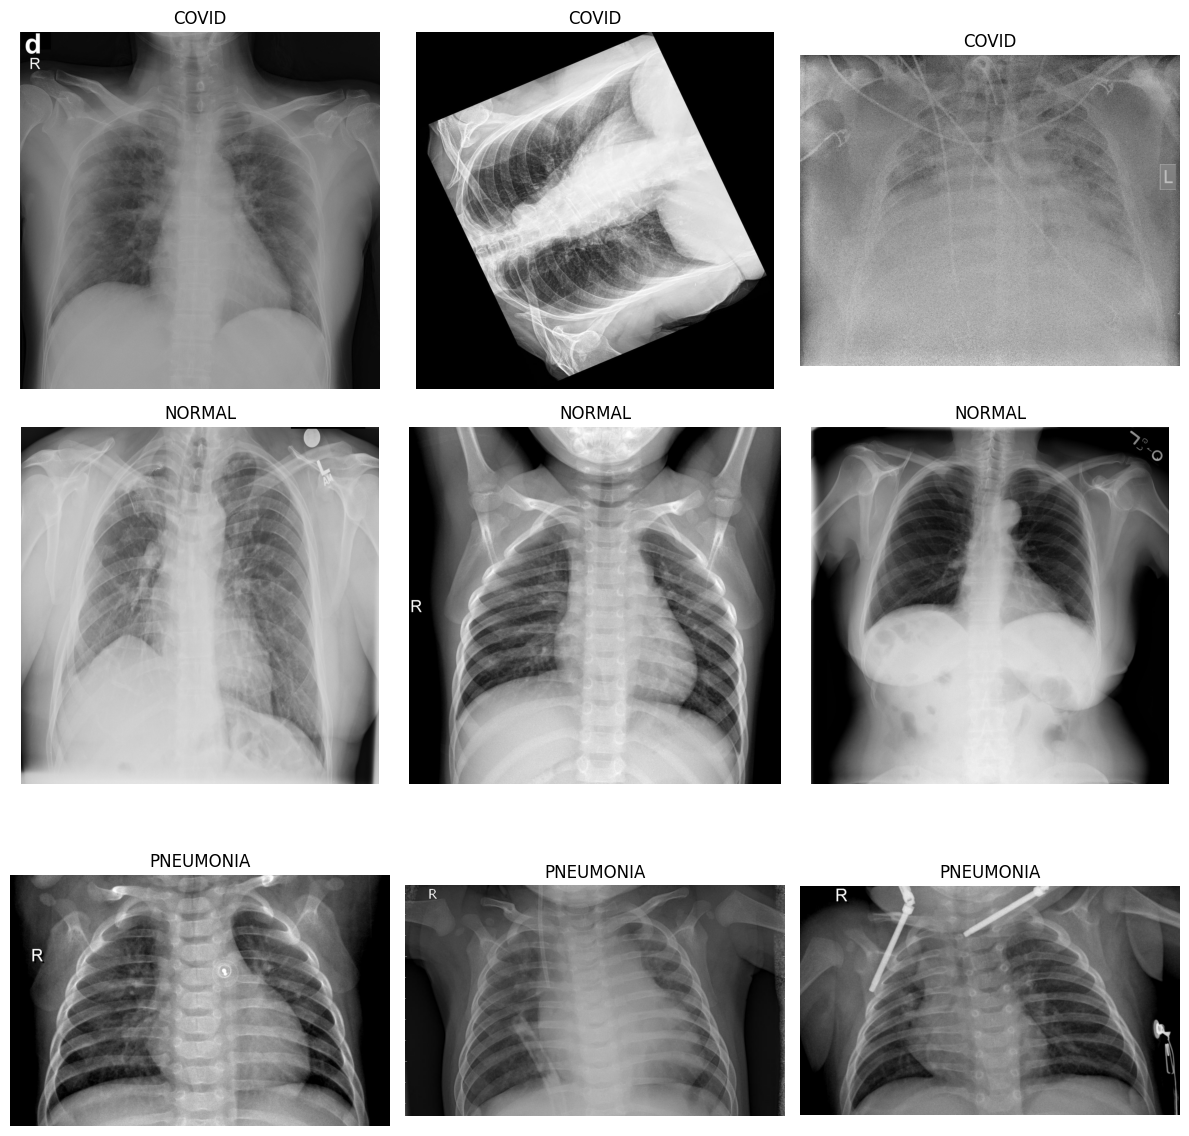

In [6]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

DATASET_PATH = (
    "/content/drive/MyDrive/"
    "COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset"
)

random.seed(42)
classes = ["covid", "normal", "pneumonia"]
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, cls in enumerate(classes):
    folder = os.path.join(DATASET_PATH, cls)

    paths = []
    for root, _, files in os.walk(folder):
        for filename in files:
            if os.path.splitext(filename)[1].lower() in extensions:
                paths.append(os.path.join(root, filename))

    samples = random.sample(paths, min(3, len(paths)))

    for col in range(3):
        ax = axes[row, col]

        if col < len(samples):
            with Image.open(samples[col]) as img:
                ax.imshow(img.convert("RGB"), cmap="gray")

            ax.set_title(cls.upper())
        ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
import os

DATASET_PATH = (
    "/content/drive/MyDrive/"
    "COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset"
)

for cls in ["covid", "normal", "pneumonia"]:
    folder = os.path.join(DATASET_PATH, cls)

    subfolders = [
        name for name in os.listdir(folder)
        if os.path.isdir(os.path.join(folder, name))
    ]

    print(f"\n{cls.upper()}")
    print("Subfolders:", subfolders[:10] if subfolders else "None")
    print("Top-level files:", sum(
        os.path.isfile(os.path.join(folder, name))
        for name in os.listdir(folder)
    ))


COVID
Subfolders: None
Top-level files: 2313

NORMAL
Subfolders: None
Top-level files: 2313

PNEUMONIA
Subfolders: None
Top-level files: 2313


In [8]:
import os
from collections import Counter

DATASET_PATH = (
    "/content/drive/MyDrive/"
    "COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset"
)

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for cls in ["covid", "normal", "pneumonia"]:
    folder = os.path.join(DATASET_PATH, cls)
    counts = Counter()
    non_image_files = []

    for name in os.listdir(folder):
        path = os.path.join(folder, name)

        if not os.path.isfile(path):
            continue

        ext = os.path.splitext(name)[1].lower()

        if ext in extensions:
            counts[ext] += 1
        else:
            non_image_files.append(name)

    print(f"\n{cls.upper()}")
    print("Image count:", sum(counts.values()))
    print("Formats:", dict(counts))
    print("Non-image files:", len(non_image_files))
    if non_image_files:
        print("Examples:", non_image_files[:5])


COVID
Image count: 2276
Formats: {'.jpg': 1725, '.jpeg': 218, '.png': 333}
Non-image files: 37
Examples: ['253.jfif', '364.jfif', '368.jfif', '372.jfif', '406.jfif']

NORMAL
Image count: 2313
Formats: {'.png': 1977, '.jpeg': 336}
Non-image files: 0

PNEUMONIA
Image count: 2313
Formats: {'.jpeg': 2137, '.png': 176}
Non-image files: 0


In [1]:
import os
from PIL import Image

folder = "/content/drive/MyDrive/COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset/covid"
files = [f for f in os.listdir(folder) if f.lower().endswith(".jfif")]

print("JFIF files:", len(files))

bad = []
for f in files:
    try:
        with Image.open(os.path.join(folder, f)) as img:
            img.verify()
    except Exception:
        bad.append(f)

print("Readable:", len(files) - len(bad))
print("Unreadable:", len(bad))
print("Examples:", bad[:5])

JFIF files: 37
Readable: 37
Unreadable: 0
Examples: []


In [4]:
import os, pandas as pd
from sklearn.model_selection import train_test_split

root = "/content/drive/MyDrive/COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset"
rows = []
exts = (".jpg", ".jpeg", ".jfif", ".png", ".bmp", ".webp")

for cls in ["covid", "normal", "pneumonia"]:
    folder = os.path.join(root, cls)
    for f in os.listdir(folder):
        if f.lower().endswith(exts) and os.path.isfile(os.path.join(folder, f)):
            rows.append({"path": os.path.join(folder, f), "label": cls})

df = pd.DataFrame(rows)
train, temp = train_test_split(
    df, test_size=0.2, stratify=df["label"], random_state=42
)
val, test = train_test_split(
    temp, test_size=0.5, stratify=temp["label"], random_state=42
)

train["split"], val["split"], test["split"] = "train", "val", "test"
manifest = pd.concat([train, val, test]).sample(frac=1, random_state=42)
manifest.to_csv("/content/covid_dataset_split.csv", index=False)

print("Total:", len(manifest))
print(manifest.groupby(["split", "label"]).size())
print("Saved: /content/covid_dataset_split.csv")

Total: 6939
split  label    
test   covid         231
       normal        232
       pneumonia     231
train  covid        1851
       normal       1850
       pneumonia    1850
val    covid         231
       normal        231
       pneumonia     232
dtype: int64
Saved: /content/covid_dataset_split.csv


In [5]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
import tensorflow as tf
import pandas as pd
import os

CSV_PATH = "/content/covid_dataset_split.csv"
IMG_SIZE = 224
BATCH_SIZE = 32
CLASSES = ["covid", "normal", "pneumonia"]

df = pd.read_csv(CSV_PATH)

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32)
    return img, label

def make_ds(split, shuffle=False):
    part = df[df["split"] == split]
    labels = tf.constant([CLASSES.index(x) for x in part["label"]])
    ds = tf.data.Dataset.from_tensor_slices((part["path"].values, labels))
    if shuffle:
        ds = ds.shuffle(1500, seed=42)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds("train", shuffle=True)
val_ds = make_ds("val")
test_ds = make_ds("test")

base = tf.keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.applications.efficientnet.preprocess_input(inputs)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(3, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Quick smoke test: one batch only
images, labels = next(iter(train_ds))
print("Batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Prediction shape:", model(images).shape)
print("Model ready!")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Batch shape: (32, 224, 224, 3)
Labels shape: (32,)
Prediction shape: (32, 3)
Model ready!


In [7]:
import time
import tensorflow as tf

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_efficientnet.keras",
        monitor="val_loss", save_best_only=True
    )
]

start = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=callbacks
)

print(f"Training time: {(time.time()-start)/60:.1f} minutes")

Epoch 1/3
174/174 ━━━━━━━━━━━━━━━━━━━━ 1529s 9s/step - accuracy: 0.8199 - loss: 0.4994 - val_accuracy: 0.8790 - val_loss: 0.3457
Epoch 2/3
174/174 ━━━━━━━━━━━━━━━━━━━━ 55s 317ms/step - accuracy: 0.8829 - loss: 0.3487 - val_accuracy: 0.9049 - val_loss: 0.3043
Epoch 3/3
174/174 ━━━━━━━━━━━━━━━━━━━━ 51s 294ms/step - accuracy: 0.9015 - loss: 0.3030 - val_accuracy: 0.9006 - val_loss: 0.2659
Training time: 27.8 minutes


In [9]:
import numpy as np
from sklearn.metrics import classification_report, accuracy_score

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)

print("Test Accuracy:", round(accuracy_score(y_true, y_pred)*100, 2), "%")
print(classification_report(
    y_true, y_pred,
    target_names=["COVID", "Normal", "Pneumonia"]
))

Test Accuracy: 91.79 %
              precision    recall  f1-score   support

       COVID       0.94      0.94      0.94       231
      Normal       0.88      0.89      0.88       232
   Pneumonia       0.94      0.92      0.93       231

    accuracy                           0.92       694
   macro avg       0.92      0.92      0.92       694
weighted avg       0.92      0.92      0.92       694



In [10]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import random

# Pick one test image
sample = df[df["split"] == "test"].sample(1, random_state=42).iloc[0]
img_path = sample["path"]
true_label = sample["label"]

# Load image
img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
img_array = tf.keras.utils.img_to_array(img)
input_array = np.expand_dims(img_array, axis=0)

# Predict
pred = model.predict(input_array, verbose=0)[0]
pred_idx = np.argmax(pred)
class_names = ["COVID", "Normal", "Pneumonia"]

print("True label:", true_label)
print("Predicted:", class_names[pred_idx])
print("Confidence:", round(float(pred[pred_idx]) * 100, 2), "%")

True label: normal
Predicted: Normal
Confidence: 89.09 %


In [14]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

base = model.get_layer("efficientnetb0")
last_conv = base.get_layer("top_conv")

# Create a feature extractor from EfficientNet
feature_extractor = tf.keras.Model(
    base.inputs, last_conv.output
)

# Connect the classifier to the extracted feature map
inp = tf.keras.Input(shape=(224, 224, 3))
features = feature_extractor(inp, training=False)
x = base.output  # Not used for classifier

In [15]:
for i, layer in enumerate(model.layers):
    print(i, layer.name, layer.output.shape if hasattr(layer, "output") else "")

0 input_layer_1 (None, 224, 224, 3)
1 efficientnetb0 (None, 7, 7, 1280)
2 global_average_pooling2d (None, 1280)
3 dropout (None, 1280)
4 dense (None, 3)


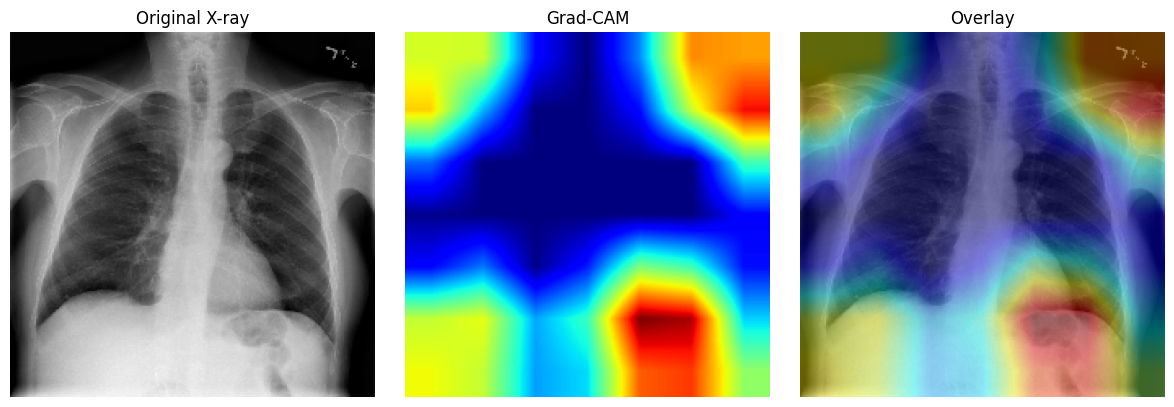

In [17]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

base = model.get_layer("efficientnetb0")
conv_layer = base.get_layer("top_conv")

# Model that returns convolutional activations
feature_model = tf.keras.Model(
    inputs=base.input,
    outputs=conv_layer.output
)

# Run with a real tensor under GradientTape
x = tf.convert_to_tensor(input_array, dtype=tf.float32)

with tf.GradientTape() as tape:
    features = feature_model(x, training=False)
    tape.watch(features)

    # Continue through EfficientNet's remaining layers
    z = features
    for layer in base.layers[base.layers.index(conv_layer) + 1:]:
        z = layer(z, training=False)

    z = model.get_layer("global_average_pooling2d")(z)
    z = model.get_layer("dropout")(z, training=False)
    preds = model.get_layer("dense")(z)
    class_idx = tf.argmax(preds[0])
    score = preds[:, class_idx]

grads = tape.gradient(score, features)
weights = tf.reduce_mean(grads, axis=(1, 2))
heatmap = tf.reduce_sum(features * weights[:, None, None, :], axis=-1)[0]
heatmap = tf.maximum(heatmap, 0)
heatmap /= tf.reduce_max(heatmap) + 1e-8
heatmap = cv2.resize(heatmap.numpy(), (224, 224))

original = input_array[0].astype("uint8")
heat = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
overlay = cv2.addWeighted(
    cv2.cvtColor(original, cv2.COLOR_RGB2BGR), 0.6, heat, 0.4, 0
)
overlay = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 4))
for i, (im, title) in enumerate([
    (original, "Original X-ray"),
    (heatmap, "Grad-CAM"),
    (overlay, "Overlay")
]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(im, cmap="jet" if i == 1 else None)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

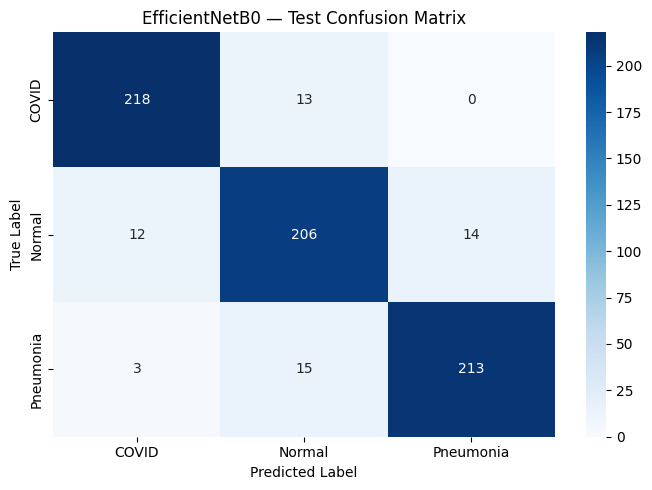

              precision    recall  f1-score   support

       COVID     0.9356    0.9437    0.9397       231
      Normal     0.8803    0.8879    0.8841       232
   Pneumonia     0.9383    0.9221    0.9301       231

    accuracy                         0.9179       694
   macro avg     0.9181    0.9179    0.9180       694
weighted avg     0.9180    0.9179    0.9179       694



In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

class_names = ["COVID", "Normal", "Pneumonia"]

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("EfficientNetB0 — Test Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_true, y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    digits=4
))

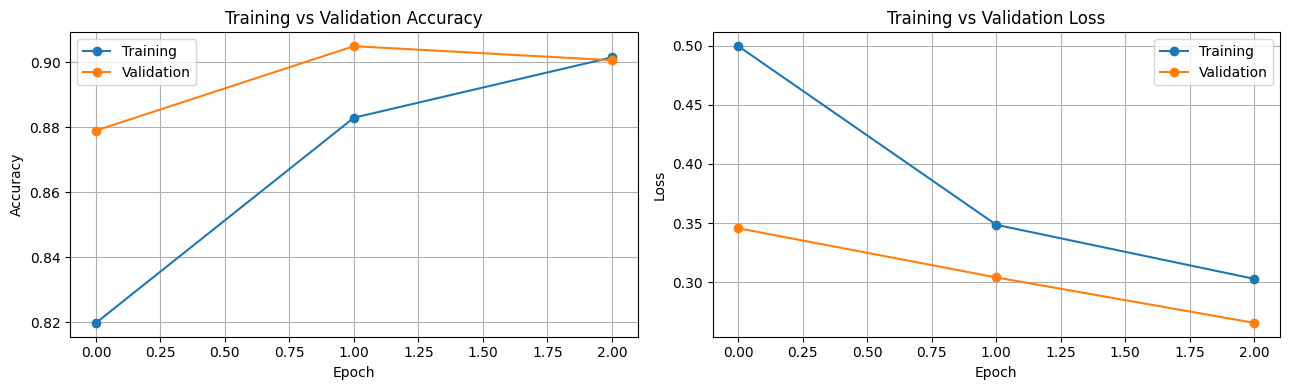

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(history.history["accuracy"], marker="o", label="Training")
ax[0].plot(history.history["val_accuracy"], marker="o", label="Validation")
ax[0].set_title("Training vs Validation Accuracy")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Accuracy")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(history.history["loss"], marker="o", label="Training")
ax[1].plot(history.history["val_loss"], marker="o", label="Validation")
ax[1].set_title("Training vs Validation Loss")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Loss")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

Predicted class: Normal
Mean probability: 83.78%
Prediction variability: 10.91%


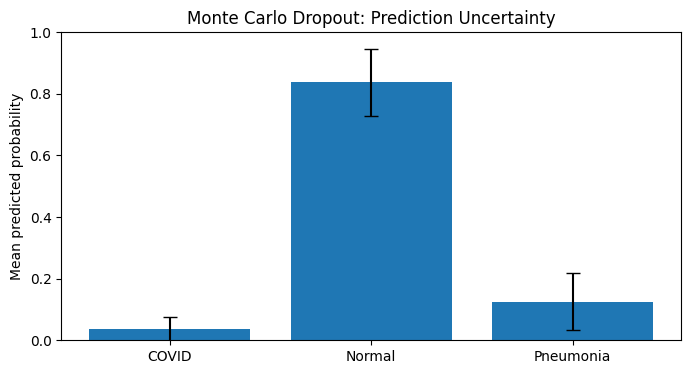

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Use the test X-ray selected earlier
x = tf.convert_to_tensor(input_array, dtype=tf.float32)

# Build a model that keeps dropout active during inference
mc_model = tf.keras.Model(
    inputs=model.input,
    outputs=model.get_layer("dropout").output
)

# Apply the trained classification layer after dropout
dense_layer = model.get_layer("dense")

samples = []
for _ in range(30):
    features = mc_model(x, training=True)
    probs = dense_layer(features).numpy()[0]
    probs = probs / (probs.sum() + 1e-8)
    samples.append(probs)

samples = np.array(samples)
mean_probs = samples.mean(axis=0)
std_probs = samples.std(axis=0)

class_names = ["COVID", "Normal", "Pneumonia"]
pred_idx = np.argmax(mean_probs)

print("Predicted class:", class_names[pred_idx])
print("Mean probability:", f"{mean_probs[pred_idx] * 100:.2f}%")
print("Prediction variability:", f"{std_probs[pred_idx] * 100:.2f}%")

plt.figure(figsize=(8, 4))
plt.bar(class_names, mean_probs, yerr=std_probs, capsize=5)
plt.ylabel("Mean predicted probability")
plt.title("Monte Carlo Dropout: Prediction Uncertainty")
plt.ylim(0, 1)
plt.show()

In [21]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score

y_true = []
y_original = []
y_bright = []

for images, labels in test_ds:
    original_probs = model.predict(images, verbose=0)

    # Increase brightness while keeping pixels in the 0–255 range
    bright_images = tf.clip_by_value(images * 1.2, 0, 255)
    bright_probs = model.predict(bright_images, verbose=0)

    y_true.extend(labels.numpy())
    y_original.extend(np.argmax(original_probs, axis=1))
    y_bright.extend(np.argmax(bright_probs, axis=1))

acc_original = accuracy_score(y_true, y_original)
acc_bright = accuracy_score(y_true, y_bright)

print(f"Original test accuracy: {acc_original * 100:.2f}%")
print(f"Brightened test accuracy: {acc_bright * 100:.2f}%")
print(f"Accuracy change: {(acc_bright - acc_original) * 100:+.2f} percentage points")

Original test accuracy: 91.79%
Brightened test accuracy: 90.92%
Accuracy change: -0.86 percentage points


In [22]:
model.save("/content/EfficientNetB0_COVID_Model.keras")
print("Model saved successfully!")

Model saved successfully!


In [23]:
from google.colab import files
files.download("/content/EfficientNetB0_COVID_Model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
import pandas as pd

results = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "COVID F1-score",
        "Normal F1-score",
        "Pneumonia F1-score",
        "Brightened Test Accuracy"
    ],
    "Score (%)": [91.79, 93.97, 88.41, 93.01, 90.92]
})

display(results)
results.to_csv("/content/EfficientNetB0_Results.csv", index=False)

,Metric,Score (%)
0,Test Accuracy,91.79
1,COVID F1-score,93.97
2,Normal F1-score,88.41
3,Pneumonia F1-score,93.01
4,Brightened Test Accuracy,90.92


In [25]:
results.to_csv("/content/EfficientNetB0_Results.csv", index=False)

from google.colab import files
files.download("/content/EfficientNetB0_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>